# Descricao do Projeto: 

Você trabalha em uma startup que vende produtos alimentícios. Você precisa analisar o comportamento do usuário para o aplicativo da empresa.

Primeiro, estude o funil de vendas. Descubra como os usuários chegam à etapa de compra.  usuários realmente chegam a essa etapa? Quantos ficam presos nas fases anteriores? Quais etapas em particular?

Em seguida, veja os resultados do teste A/A/B. (Continue lendo para obter mais informação sobre os testes A/A/B). Os designers gostariam de alterar as fontes de todo o aplicativo, mas os gerentes temem que os usuários achem o novo design intimidador. Eles decidem tomar a decisão com base nos resultados de um teste A/A/B.

Os usuários são divididos em três grupos: dois grupos de controle recebem as fontes antigas e um grupo de teste recebe as novas. Descubra qual conjunto de fontes produz melhores resultados.

A criação de dois grupos A tem certas vantagens. Podemos adaptar um princípio segundo o qual só estaremos confiantes na precisão de nossos testes quando os dois grupos de controle forem semelhantes. Se houver diferenças significativas entre os grupos A, isso pode nos ajudar a descobrir fatores que podem distorcer os resultados. A comparação de grupos de controle também nos informa de quanto tempo e dados precisaremos ao executar outros testes.

Você usará o mesmo conjunto de dados para análise geral e análise A/A/B. Em projetos reais, os experimentos se realizam constantemente. Os analistas estudam a qualidade de um aplicativo usando dados gerais, sem prestar atenção na participação dos usuários em experimentos.

### Descrição dos dados
Cada linha do registro (também referido como log) é uma ação do usuário ou um evento.

EventName — nome do evento
DeviceIDHash — identificador de usuário exclusivo
EventTimestamp — hora do evento
ExpId — número do experimento: 246 e 247 são os grupos de controle, 248 é o grupo de teste


In [227]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats as st
from statsmodels.stats.proportion import proportions_ztest

In [228]:
df_logs = pd.read_csv('../data/logs_exp_us.csv', sep='\t')
df_logs.columns = df_logs.columns.str.strip()
df_logs.head()

,EventName,DeviceIDHash,EventTimestamp,ExpId
0,MainScreenAppear,4575588528974610257,1564029816,246
1,MainScreenAppear,7416695313311560658,1564053102,246
2,PaymentScreenSuccessful,3518123091307005509,1564054127,248
3,CartScreenAppear,3518123091307005509,1564054127,248
4,PaymentScreenSuccessful,6217807653094995999,1564055322,248


In [229]:
df_logs = df_logs.rename(
    columns={
        'EventName': 'event_name',
        'DeviceIDHash': 'device_id_hash',
        'EventTimestamp': 'time_stamp',
        'ExpId': 'exp_id'
    }
)
df_logs.head()

,event_name,device_id_hash,time_stamp,exp_id
0,MainScreenAppear,4575588528974610257,1564029816,246
1,MainScreenAppear,7416695313311560658,1564053102,246
2,PaymentScreenSuccessful,3518123091307005509,1564054127,248
3,CartScreenAppear,3518123091307005509,1564054127,248
4,PaymentScreenSuccessful,6217807653094995999,1564055322,248


In [230]:
df_logs.info()

<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   event_name      244126 non-null  str  
 1   device_id_hash  244126 non-null  int64
 2   time_stamp      244126 non-null  int64
 3   exp_id          244126 non-null  int64
dtypes: int64(3), str(1)
memory usage: 7.5 MB


In [231]:
df_logs['time_stamp'] = pd.to_datetime(df_logs['time_stamp'], unit='s')

df_logs['date'] = df_logs['time_stamp'].dt.date
df_logs['hours'] = df_logs['time_stamp'].dt.hour

df_logs.head()

,event_name,device_id_hash,time_stamp,exp_id,date,hours
0,MainScreenAppear,4575588528974610257,2019-07-25 04:43:36,246,2019-07-25,4
1,MainScreenAppear,7416695313311560658,2019-07-25 11:11:42,246,2019-07-25,11
2,PaymentScreenSuccessful,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25,11
3,CartScreenAppear,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25,11
4,PaymentScreenSuccessful,6217807653094995999,2019-07-25 11:48:42,248,2019-07-25,11


In [232]:
print(df_logs.duplicated().sum())

413


In [233]:
df_logs[df_logs.duplicated(keep=False)].sort_values(
    ['device_id_hash', 'time_stamp']
).head(20)

,event_name,device_id_hash,time_stamp,exp_id,date,hours
130557,MainScreenAppear,33176906322804559,2019-08-04 15:37:55,248,2019-08-04,15
130558,MainScreenAppear,33176906322804559,2019-08-04 15:37:55,248,2019-08-04,15
130994,OffersScreenAppear,33176906322804559,2019-08-04 15:49:23,248,2019-08-04,15
130995,OffersScreenAppear,33176906322804559,2019-08-04 15:49:23,248,2019-08-04,15
104106,CartScreenAppear,34565258828294726,2019-08-03 18:33:41,248,2019-08-03,18
104108,CartScreenAppear,34565258828294726,2019-08-03 18:33:41,248,2019-08-03,18
159301,PaymentScreenSuccessful,54903596035630984,2019-08-05 13:27:52,248,2019-08-05,13
159302,PaymentScreenSuccessful,54903596035630984,2019-08-05 13:27:52,248,2019-08-05,13
176812,PaymentScreenSuccessful,77364241990273403,2019-08-05 22:38:52,246,2019-08-05,22
176813,PaymentScreenSuccessful,77364241990273403,2019-08-05 22:38:52,246,2019-08-05,22


In [234]:
df_logs = df_logs.drop_duplicates()
print(df_logs.duplicated().sum())

0


In [235]:
df_logs.info()

<class 'pandas.DataFrame'>
Index: 243713 entries, 0 to 244125
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype        
---  ------          --------------   -----        
 0   event_name      243713 non-null  str          
 1   device_id_hash  243713 non-null  int64        
 2   time_stamp      243713 non-null  datetime64[s]
 3   exp_id          243713 non-null  int64        
 4   date            243713 non-null  object       
 5   hours           243713 non-null  int32        
dtypes: datetime64[s](1), int32(1), int64(2), object(1), str(1)
memory usage: 12.1+ MB


In [236]:
df_logs['date'] = pd.to_datetime(df_logs['date'])
df_logs.info()

<class 'pandas.DataFrame'>
Index: 243713 entries, 0 to 244125
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype        
---  ------          --------------   -----        
 0   event_name      243713 non-null  str          
 1   device_id_hash  243713 non-null  int64        
 2   time_stamp      243713 non-null  datetime64[s]
 3   exp_id          243713 non-null  int64        
 4   date            243713 non-null  datetime64[s]
 5   hours           243713 non-null  int32        
dtypes: datetime64[s](2), int32(1), int64(2), str(1)
memory usage: 12.1 MB


##### Analisando os dados descobrimos 413 duplicados, verificamos que os registros apresentam os mesmos valores de evento, usuario, timestamp e grupo experimental, e por isso foi considerado registros duplicados, decidindo remove-los antes da analise do funil e do experimento. 

### 3. Estude e verifique os dados

- Quantos eventos ficam nos registros?

In [237]:
logs_total = len(df_logs)

print(logs_total)

243713


- Quantos usuários ficam nos registros?

In [238]:
logs_user = df_logs['device_id_hash'].nunique()
print(logs_user)

7551


- Qual é o número médio de eventos por usuário?

In [239]:
logs_avg_user = logs_total / logs_user

print(f"Average events per user: {logs_avg_user}")

Average events per user: 32.27559263673685


- Qual é o período de tempo que os dados cobrem? Encontre as datas máxima e mínima. Desenhe um histograma por data e hora. Você pode ter certeza de que possui os dados igualmente completos para todo o período? Os eventos mais antigos podem acabar aparecendo nos diários de alguns usuários por motivos técnicos, e isso pode distorcer o quadro geral. Encontre o momento em que os dados começam a ser completos e ignore a seção anterior. Qual período os dados realmente representam?

In [240]:
date_min = df_logs['time_stamp'].min()
date_max = df_logs['time_stamp'].max()

print(date_min)
print(date_max)

2019-07-25 04:43:36
2019-08-07 21:15:17


In [241]:
events_per_day = df_logs["date"].value_counts().sort_index()

print(events_per_day)

date
2019-07-25        9
2019-07-26       31
2019-07-27       55
2019-07-28      105
2019-07-29      184
2019-07-30      412
2019-07-31     2030
2019-08-01    36141
2019-08-02    35554
2019-08-03    33282
2019-08-04    32968
2019-08-05    36058
2019-08-06    35788
2019-08-07    31096
Name: count, dtype: int64


In [242]:
before_0108 = df_logs[df_logs['date'] < "2019-08-01"].shape[0]
user_0108 = df_logs[df_logs['date'] < "2019-08-01"]['device_id_hash'].nunique()

print(before_0108)
print(user_0108)
percentage = (df_logs[df_logs['date'] < "2019-08-01"].shape[0] / len(df_logs)) * 100

print(percentage)

2826
1451
1.159560630741897


In [243]:
df_logs_full_users = df_logs['device_id_hash'].nunique()
df_logs_filtered = df_logs[df_logs['date'] >= "2019-08-01"]
df_logs_filtered_users = df_logs_filtered['device_id_hash'].nunique()

lost_users= df_logs_full_users - df_logs_filtered_users

lost_users

17

In [244]:
df_filtered = df_logs_filtered['exp_id'].value_counts()
group_filtered = df_logs_filtered.groupby('exp_id')['device_id_hash'].nunique()

print(df_filtered)
print(group_filtered)

exp_id
248    84563
246    79302
247    77022
Name: count, dtype: int64
exp_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64


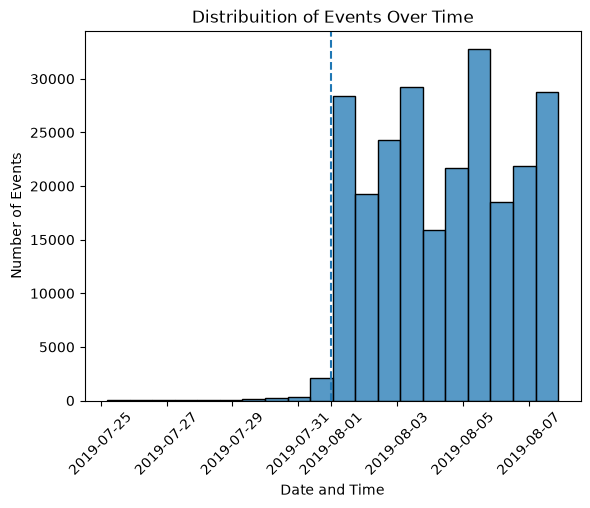

In [245]:
sns.histplot(data=df_logs, x='time_stamp', bins=20)

plt.axvline(
    pd.Timestamp("2019-08-01"),
    linestyle='--',
    label="Start of complete data"
)

plt.title('Distribuition of Events Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Number of Events')
plt.xticks(rotation=45)
plt.show()

In [246]:
df_filtered = df_logs[df_logs["date"] >= "2019-08-01"].copy()

##### Pelas analises os dados abrangem o periodo de **25/07/2019 a 07/08/2019**. A partir de **01/08**, o volume de eventos se torna significativamente maior e mais consistente, indicando que os dados anteriores estavam incompletos. O período anterior a 01/08 representa apenas **1,16% dos eventos** e sua remoção resulta na perda de apenas **17 usuários**. Portanto, a análise será realizada com os dados de **01/08/2019 a 07/08/2019**. Os três grupos experimentais (**246, 247 e 248**) estão representados nos dados filtrados.

### 4. Estude o funil de eventos

- Veja quais eventos estão nos diários e sua frequência de ocorrência. Classifique-os por frequência.

In [247]:
event_name_count = df_filtered['event_name'].value_counts()
print(event_name_count)

event_name
MainScreenAppear           117328
OffersScreenAppear          46333
CartScreenAppear            42303
PaymentScreenSuccessful     33918
Tutorial                     1005
Name: count, dtype: int64


- Encontre o número de usuários que executaram cada uma dessas ações. Ordene os eventos pelo número de usuários. Calcule a proporção de usuários que executaram a ação pelo menos uma vez.

In [248]:
group_event_user = df_filtered.groupby('event_name')['device_id_hash'].nunique().reset_index()

group_event_user.columns = ['event_name', 'unique_users']

total_users =df_filtered['device_id_hash'].nunique()
group_event_user['user_percentage'] = (group_event_user['unique_users'] / total_users) * 100
group_event_user = group_event_user.sort_values(by='unique_users', ascending=False).reset_index(drop=True)

group_event_user


,event_name,unique_users,user_percentage
0,MainScreenAppear,7419,98.473586
1,OffersScreenAppear,4593,60.963632
2,CartScreenAppear,3734,49.561986
3,PaymentScreenSuccessful,3539,46.973719
4,Tutorial,840,11.149456


- Em que ordem você acha que as ações ocorreram? Todos elas fazem parte de uma única sequência? Você não precisa levá-las em consideração ao calcular o funil.

In [249]:
group_event_user['previous_user'] = group_event_user['unique_users'].shift(1)

group_event_user['conversion_rate'] = (
    group_event_user['unique_users'] / 
    group_event_user['previous_user']
) * 100

group_event_user


,event_name,unique_users,user_percentage,previous_user,conversion_rate
0,MainScreenAppear,7419,98.473586,NaN,NaN
1,OffersScreenAppear,4593,60.963632,7419.0,61.908613
2,CartScreenAppear,3734,49.561986,4593.0,81.297627
3,PaymentScreenSuccessful,3539,46.973719,3734.0,94.777718
4,Tutorial,840,11.149456,3539.0,23.735519


##### A sequencia mais provavel do fluxo principal e MainScreenAppear - OffersScreenAppear - CartScreenAppear - PaymentScreenSuccessful. O evento Tutorial parece ser independente desse fluxo principal, pois nao representa necessariamente uma etapa da jornada de compra. E observamos que a fase que mais perdemos usuarios acontece entre, MainScreenAppear e OffersScreenAppear sendo apenas **61,91%** dos usuarios que chegam a tela principal avancaram para a tela de ofertas. Depois disso o funil fica muito mais eficiente, sendo Offers para Cart de **81,30%** e Cart para Payment de **94,78%**. Concluindo que o principal problema estar no inicio da jornada. 

- Qual é a parcela de usuários que faz o caminho inteiro, desde o primeiro evento até o pagamento?

In [250]:
full_funnel_conversion = (
    group_event_user.loc[
        group_event_user['event_name'] == 'PaymentScreenSuccessful', 'unique_users'	
    ].iloc[0] 
    /
    group_event_user.loc[
            group_event_user['event_name'] == 'MainScreenAppear', 'unique_users'	
        ].iloc[0] 
) * 100

print(f"Users who complete the entire journey from the first event to payment: {full_funnel_conversion:.2f}%")

Users who complete the entire journey from the first event to payment: 47.70%


### 5. Estude os resultados do experimento

- Quantos usuários há em cada grupo?

In [251]:
group_type_user = df_filtered.groupby("exp_id")["device_id_hash"].nunique()

group_type_user

exp_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64

- Temos dois grupos de controle no teste A/A, no qual verificamos nossos mecanismos e cálculos. Veja se há uma diferença estatisticamente significativa entre as amostragens 246 e 247.

In [252]:
users246 = df_filtered[
    (df_filtered['exp_id'] == 246) &
    (df_filtered['event_name'] == 'MainScreenAppear')
]['device_id_hash'].nunique()

users247 = df_filtered[
    (df_filtered['exp_id'] == 247) &
    (df_filtered['event_name'] == 'MainScreenAppear')
]['device_id_hash'].nunique()

users246, users247

(2450, 2476)

In [253]:
p_246 = (users246 / 2484) * 100
p_247 = (users247 / 2513) * 100

print(f"Group 246: {p_246:.2f}%")
print(f"Group 247: {p_247:.2f}%")

Group 246: 98.63%
Group 247: 98.53%


In [254]:
users246 = 2450
users247 = 2476

successes = [users246, users247]
nobs = [2484, 2513]

alpha = 0.05

stat, p_value = proportions_ztest(
    count=successes,
    nobs=nobs
)

print('p_value', p_value)

if p_value < alpha:
    print("Há diferença estatisticamente significativa entre os grupos 246 e 247.")
else:
    print("Não há diferença estatisticamente significativa entre os grupos 246 e 247.")

p_value 0.7570597232046099
Não há diferença estatisticamente significativa entre os grupos 246 e 247.


- Selecione o evento mais popular. Em cada um dos grupos de controle, encontre o número de usuários que realizaram essa ação. Encontre a proporção deles. Verifique se a diferença entre os grupos é estatisticamente significativa. Repita o procedimento para todos os outros eventos (economizará tempo se você criar uma função especial para este teste). Você pode confirmar se os grupos foram divididos corretamente?

In [258]:
def test_proportions(event, group1, group2):
    users_group1 = df_filtered[
        (df_filtered['exp_id'].isin(group1)) &
        (df_filtered['event_name'] == event)
    ]['device_id_hash'].nunique()
    users_group2 = df_filtered[
        (df_filtered['exp_id'].isin(group2)) &
        (df_filtered['event_name'] == event)
    ]['device_id_hash'].nunique()

    total_group1 = df_filtered[
        df_filtered['exp_id'].isin(group1)
    ]['device_id_hash'].nunique()

    total_group2 = df_filtered[
            df_filtered['exp_id'].isin(group2)
        ]['device_id_hash'].nunique()

    successes = [users_group1, users_group2]
    nobs = [total_group1, total_group2]

    stat, p_value = proportions_ztest(
        count=successes,
        nobs=nobs
    )
    return p_value

events = [
    "MainScreenAppear",
    "OffersScreenAppear",
    "CartScreenAppear",
    "PaymentScreenSuccessful"
]
for event in events:
    p_value = test_proportions(event, [246], [247])
    print(f"{event}: p-value = {p_value:.4f}")

MainScreenAppear: p-value = 0.7571
OffersScreenAppear: p-value = 0.2481
CartScreenAppear: p-value = 0.2288
PaymentScreenSuccessful: p-value = 0.1146


##### Analisando os valor p de cada evento sendo o resultado dos grupos 246 e 247, concluimos que nao encontramos evidencias de diferencas estatisticamente significativas entre os grupos. Podemos assim concluir que os dois grupos de controle apresentam comportamento estatisticamente semelhante nos eventos analisados. 

In [260]:
for event in events:
    p_value = test_proportions(event, [248], [246])
    print(f"{event}: p-value = {p_value:.4f}")

MainScreenAppear: p-value = 0.2950
OffersScreenAppear: p-value = 0.2084
CartScreenAppear: p-value = 0.0784
PaymentScreenSuccessful: p-value = 0.2123


In [261]:
for event in events:
    p_value = test_proportions(event, [248], [247])
    print(f"{event}: p-value = {p_value:.4f}")

MainScreenAppear: p-value = 0.4587
OffersScreenAppear: p-value = 0.9198
CartScreenAppear: p-value = 0.5786
PaymentScreenSuccessful: p-value = 0.7373


In [262]:
for event in events:
    p_value = test_proportions(event, [248], [246, 247])
    print(f"{event}: p-value = {p_value:.4f}")

MainScreenAppear: p-value = 0.2942
OffersScreenAppear: p-value = 0.4343
CartScreenAppear: p-value = 0.1818
PaymentScreenSuccessful: p-value = 0.6004


##### Resultados do Teste A/A/B 

Foram realizados 16 testes estatisticos utilizando um nivel de significancia de 0,05:

4 testes comparando os grupos de controle 246 e 247;
4 testes comparando o grupo 248 com o grupo 246;
4 testes comparando o grupo 248 com o grupo 247;
4 testes comparando o grupo 248 com os grupos de controle combinados (246+247).

Ate o momento, nenhum dos 16 testes apresentou diferenca estatisticamente significativa.